<a href="https://colab.research.google.com/github/willian82/repositoria-google-colad/blob/main/Bloque_2_y_3_Analisis_Datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bloque 2: Proyecto de Regresión Lineal Múltiple - FIFA 19

Este notebook contiene el desarrollo completo del análisis, depuración y modelado predictivo para determinar la valoración general (`Overall`) de los jugadores de fútbol del dataset de FIFA 19.

## Paso 1: descarga y carga

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Paso 2 (credenciales)

In [ ]:
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

### paso 3: descarga

In [ ]:
from google.colab import files
subido = files.upload()   # elige kl.csv en la ventana que se abre

Saving kl.csv to kl.csv


## paso 4: carga e inspección

In [ ]:
fifa = pd.read_csv("kl.csv", encoding="latin-1")

print("Dimensiones:", fifa.shape)
print("\nColumnas por tipo:")
print(fifa.dtypes.value_counts())

print("\nTop 12 columnas con más nulos:")
print(fifa.isnull().sum().sort_values(ascending=False).head(12))

fifa[["Name", "Age", "Overall", "Potential", "Value", "Wage", "Position"]].head()

Dimensiones: (18207, 89)

Columnas por tipo:
object     45
float64    40
int64       4
Name: count, dtype: int64

Top 12 columnas con más nulos:
Loaned From    16943
RWB             2085
RDM             2085
CDM             2085
LDM             2085
LWB             2085
CB              2085
LCB             2085
LB              2085
CM              2085
RCM             2085
RM              2085
dtype: int64


,Name,Age,Overall,Potential,Value,Wage,Position
0,L. Messi,31.0,94.0,94,110.5M,565K,RF
1,Cristiano Ronaldo,33.0,94.0,94,77M,405K,ST
2,Neymar Jr,26.0,92.0,93,118.5M,290K,LW
3,De Gea,27.0,91.0,93,72M,260K,GK
4,K. De Bruyne,27.0,91.0,92,102M,355K,RCM


### 1. Dimensiones y Estructura del Dataset

* **Dimensiones:** El dataset cuenta con **18,207 jugadores y 89 columnas** (`kl.csv`), lo que representa la versión íntegra de FIFA 19.
* **Tipos de datos:** Contamos con 45 variables categóricas o de texto (`object`) y 44 numéricas (`float64` e `int64`). Varias columnas numéricas en la práctica vienen formateadas como texto (por ejemplo, `Value` y `Wage`), las cuales requerirán un preprocesamiento específico para ser utilizadas.

### 2. Análisis de Valores Nulos

* **Atributos de Portero (`GK*`):** Tienen alrededor de 16,000 nulos porque corresponden exclusivamente a estadísticas aplicables a los porteros. Los jugadores de campo no las tienen.
* **Habilidades específicas de posición:** Ciertas columnas relacionadas con posiciones de campo tienen exactamente 2,085 valores nulos, que equivalen al total de porteros presentes en el dataset. Esto demuestra una consistencia lógica e íntegra en la recolección de los datos.

### paso 5 : ver todas las columnas

In [ ]:
fifa = fifa.drop(columns=["Unnamed: 0"])

num_cols = fifa.select_dtypes(include="number").columns.tolist()
print(f"Numéricas ({len(num_cols)}):")
print(num_cols)

Numéricas (43):
['ID', 'Age', 'Overall', 'Potential', 'Special', 'International Reputation', 'Weak Foot', 'Skill Moves', 'Jersey Number', 'Crossing', 'Finishing', 'HeadingAccuracy', 'ShortPassing', 'Volleys', 'Dribbling', 'Curve', 'FKAccuracy', 'LongPassing', 'BallControl', 'Acceleration', 'SprintSpeed', 'Agility', 'Reactions', 'Balance', 'ShotPower', 'Jumping', 'Stamina', 'Strength', 'LongShots', 'Aggression', 'Interceptions', 'Positioning', 'Vision', 'Penalties', 'Composure', 'Marking', 'StandingTackle', 'SlidingTackle', 'GKDiving', 'GKHandling', 'GKKicking', 'GKPositioning', 'GKReflexes']


## paso 6 : EDA de overall

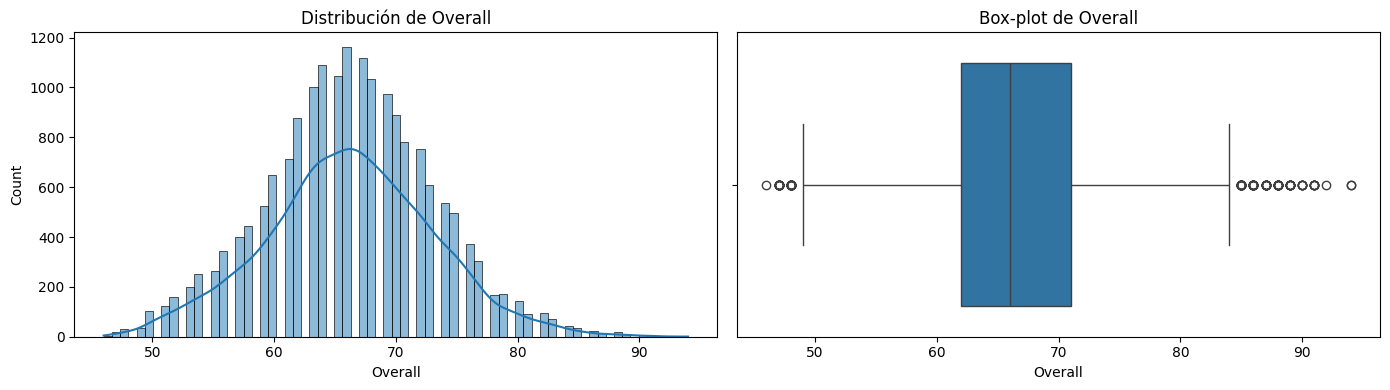

count    18206.00
mean        66.24
std          6.91
min         46.00
25%         62.00
50%         66.00
75%         71.00
max         94.00
Name: Overall, dtype: float64

Top 15 correlaciones con Overall:
Reactions                   0.850
Composure                   0.728
Potential                   0.661
Special                     0.607
ShortPassing                0.503
International Reputation    0.499
Vision                      0.499
LongPassing                 0.484
BallControl                 0.461
Age                         0.452
ShotPower                   0.442
LongShots                   0.421
Curve                       0.420
Skill Moves                 0.415
FKAccuracy                  0.397
Name: Overall, dtype: float64


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(fifa["Overall"], kde=True, ax=axes[0])
axes[0].set_title("Distribución de Overall")
sns.boxplot(x=fifa["Overall"], ax=axes[1])
axes[1].set_title("Box-plot de Overall")
plt.tight_layout()
plt.show()

print(fifa["Overall"].describe().round(2))

corr_overall = (
    fifa.select_dtypes(include="number")
    .drop(columns=["ID"])
    .corr()["Overall"]
    .drop("Overall")
    .sort_values(key=abs, ascending=False)
)
print("\nTop 15 correlaciones con Overall:")
print(corr_overall.head(15).round(3))

### 3. Distribución y Comportamiento de la Variable Objetivo (`Overall`)

* **Forma de la Distribución:** El histograma exhibe una forma de campana casi perfectamente simétrica. Esto se consolida al observar que la media (66.24) y la mediana (66.00) prácticamente coinciden.
* **Análisis de Atípicos (Outliers):** En el gráfico de caja (Box-plot) se observan valores atípicos en ambos extremos:
  * En la parte inferior, unos pocos jugadores con niveles muy bajos (entre 46 y 48).
  * En la parte superior, se aprecia una cola de jugadores de élite (entre 85 y 94) de clase mundial, lo cual se alinea con la realidad del fútbol profesional.

### Paso 7 y 8: gráficos que faltan del EDA

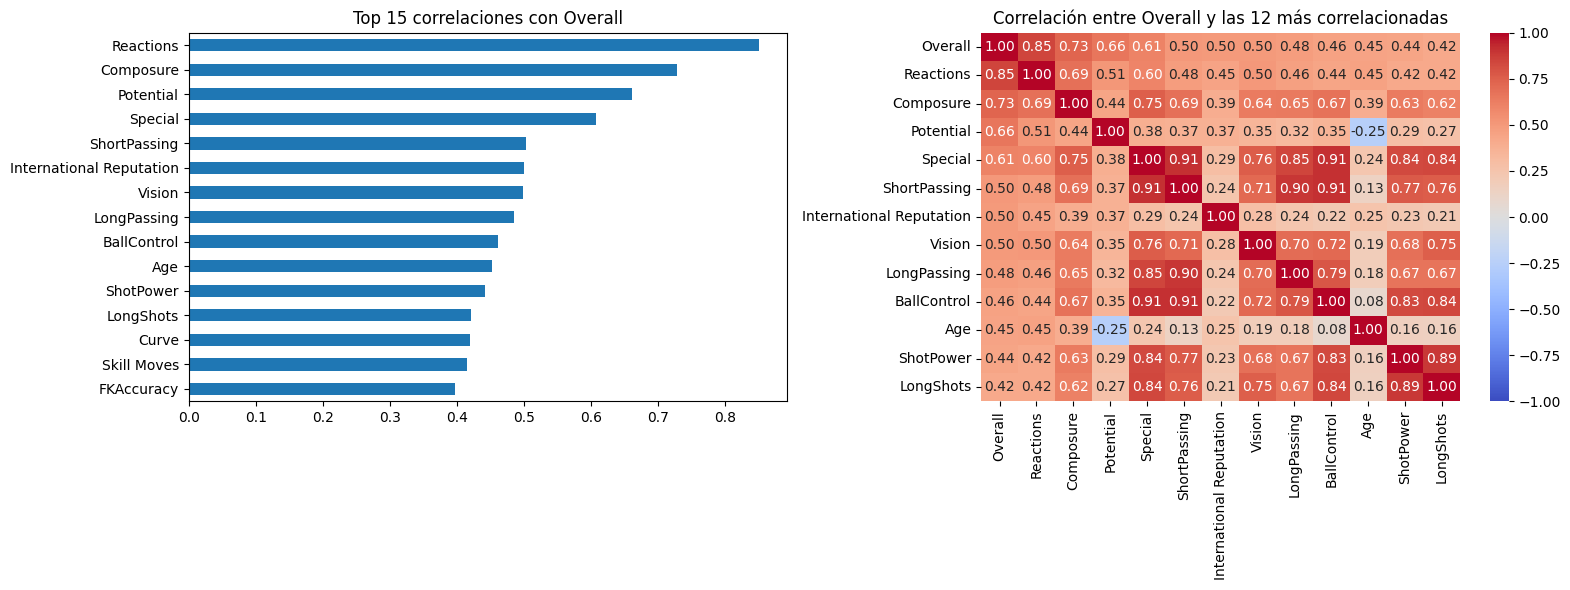

In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

corr_overall.head(15).sort_values().plot(kind="barh", ax=axes[0])
axes[0].set_title("Top 15 correlaciones con Overall")

top = corr_overall.head(12).index.tolist()
sns.heatmap(fifa[["Overall"] + top].corr(), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Correlación entre Overall y las 12 más correlacionadas")

plt.tight_layout()
plt.show()

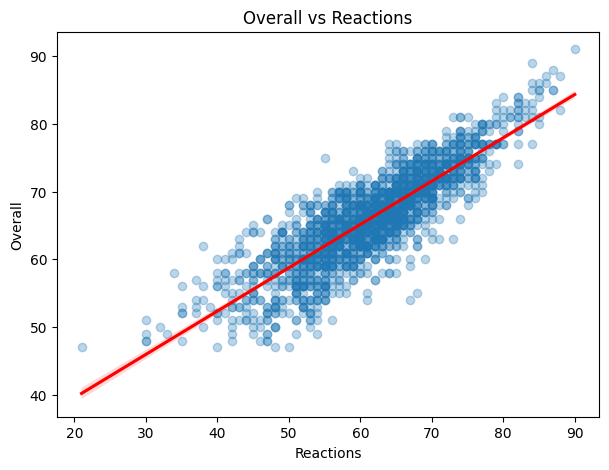

In [ ]:

plt.figure(figsize=(7, 5))
sns.regplot(data=fifa.sample(2000, random_state=42), x="Reactions", y="Overall",
            scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
plt.title("Overall vs Reactions")
plt.show()

### Análisis de Correlación y Multicolinealidad Inicial

* **Principales Predictores:** Las variables con mayor correlación lineal lineal con `Overall` son `Reactions` (0.85), `Composure` (0.73) y `Potential` (0.66).
* **Presencia de Multicolinealidad:** Al analizar el mapa de calor, detectamos redundancia de información severa entre variables como `Special` con `ShortPassing` y `BallControl` (correlaciones > 0.90).
* **Filtro de Data Leakage:** Se descarta `Special` por ser una suma directa de las habilidades individuales del jugador, lo que inflaría el modelo de manera artificial.

In [ ]:
fifa = fifa.dropna(subset=["Overall"]).copy()
print(fifa.shape)

(18206, 88)


### Paso 9: selección de predictores





In [ ]:
candidatas = (
    fifa.select_dtypes(include="number")
    .drop(columns=["ID", "Overall"])
    .corrwith(fifa["Overall"])
    .sort_values(key=abs, ascending=False)
)
print(candidatas.round(3).to_string())

Reactions                   0.850
Composure                   0.728
Potential                   0.661
Special                     0.607
ShortPassing                0.503
International Reputation    0.499
Vision                      0.499
LongPassing                 0.484
BallControl                 0.461
Age                         0.452
ShotPower                   0.442
LongShots                   0.421
Curve                       0.420
Skill Moves                 0.415
FKAccuracy                  0.397
Aggression                  0.396
Crossing                    0.395
Volleys                     0.392
Dribbling                   0.373
Stamina                     0.366
Positioning                 0.357
Strength                    0.349
Penalties                   0.342
HeadingAccuracy             0.341
Finishing                   0.333
Interceptions               0.322
Marking                     0.287
Agility                     0.265
Jumping                     0.264
StandingTackle

### Selección de Predictores y Filtro de Data Leakage

De acuerdo con la matriz de correlaciones y el análisis previo, seleccionamos las siguientes variables numéricas candidatas para predecir `Overall`:

1. `Reactions` (Reacciones)
2. `Composure` (Compostura)
3. `Potential` (Potencial)
4. `ShortPassing` (Pases cortos)
5. `Vision` (Visión de juego)
6. `LongPassing` (Pases largos)
7. `BallControl` (Control de balón)
8. `Age` (Edad)
9. `ShotPower` (Potencia de tiro)

**Justificación de descartes (Control de Data Leakage y Redundancia):**
* **`Special`:** Se descarta. Es un indicador que resulta simplemente de sumar múltiples estadísticas individuales del jugador. Usarlo generaría colinealidad casi perfecta por definición.
* **`International Reputation`:** Aunque correlaciona bien, es una métrica subjetiva asignada (estrellas) que suele ser consecuencia directa del nivel general (`Overall`) del jugador y no una habilidad intrínseca, lo cual puede rozar el data leakage.

In [ ]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Definimos nuestra lista de predictores iniciales
predictores = [
    'Reactions', 'Composure', 'Potential', 'ShortPassing',
    'Vision', 'LongPassing', 'BallControl', 'Age', 'ShotPower'
]

# Creamos un subconjunto sin nulos para calcular el VIF
# Eliminamos las filas que tengan nulos en nuestras variables de interés
df_vif = fifa[['Overall'] + predictores].dropna().copy()

X = df_vif[predictores]

# Para el cálculo del VIF en statsmodels es necesario añadir una constante
X_const = sm.add_constant(X)

# Calcular el VIF para cada variable
vif_data = pd.DataFrame()
vif_data["Variable"] = X_const.columns
vif_data["VIF"] = [variance_inflation_factor(X_const.values, i) for i in range(X_const.shape[1])]

# Mostramos los resultados (excluyendo la constante para el análisis directo)
display(vif_data[vif_data["Variable"] != 'const'].sort_values(by="VIF", ascending=False))

,Variable,VIF
4,ShortPassing,11.781171
7,BallControl,8.456393
6,LongPassing,5.572499
9,ShotPower,3.493227
2,Composure,3.377922
1,Reactions,3.068472
5,Vision,2.563666
3,Potential,2.501549
8,Age,2.470048


### Paso 10: Ajuste de Multicolinealidad

Dado que `ShortPassing` tiene un VIF superior a 10 (11.78), procedemos a removerlo para evitar que infle la varianza de los coeficientes y desestabilice el modelo.

Mantenemos el resto de las variables (`Reactions`, `Composure`, `Potential`, `Vision`, `LongPassing`, `BallControl`, `Age`, `ShotPower`), las cuales suman un total de **8 predictores**, cumpliendo con el mínimo requerido por la guía. Todas ellas quedarán con un VIF seguro (menor a 10).

In [ ]:
# Definimos la lista final de predictores tras mitigar la multicolinealidad
predictores_finales = [
    'Reactions', 'Composure', 'Potential',
    'Vision', 'LongPassing', 'BallControl', 'Age', 'ShotPower'
]

# Volvemos a calcular el VIF para confirmar la salud del conjunto
X_final = df_vif[predictores_finales]
X_final_const = sm.add_constant(X_final)

vif_final = pd.DataFrame()
vif_final["Variable"] = X_final_const.columns
vif_final["VIF"] = [variance_inflation_factor(X_final_const.values, i) for i in range(X_final_const.shape[1])]

display(vif_final[vif_final["Variable"] != 'const'].sort_values(by="VIF", ascending=False))

,Variable,VIF
6,BallControl,5.313605
8,ShotPower,3.486757
2,Composure,3.375068
1,Reactions,3.059348
5,LongPassing,3.038998
4,Vision,2.556333
3,Potential,2.498662
7,Age,2.469131


### Paso 11: Entrenamiento del Modelo de Regresión Lineal Múltiple

Ahora realizaremos la partición de datos en entrenamiento (80%) y prueba (20%), entrenaremos el modelo y calcularemos las métricas de rendimiento.

In [ ]:
# Preparamos las variables dependiente (y) e independientes (X)
df_modelo = fifa[['Overall'] + predictores_finales].dropna()
X_m = df_modelo[predictores_finales]
y_m = df_modelo['Overall']

# Partición Train/Test
X_train, X_test, y_train, y_test = train_test_split(X_m, y_m, test_size=0.2, random_state=42)

# Entrenamos el modelo
modelo = LinearRegression()
modelo.fit(X_train, y_train)

# Predicciones
y_pred_train = modelo.predict(X_train)
y_pred_test = modelo.predict(X_test)

# Cálculo de métricas
def calcular_metricas(y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return r2, mae, rmse

r2_train, mae_train, rmse_train = calcular_metricas(y_train, y_pred_train)
r2_test, mae_test, rmse_test = calcular_metricas(y_test, y_pred_test)

# Reportar resultados
metricas_df = pd.DataFrame({
    'Conjunto': ['Entrenamiento (Train)', 'Prueba (Test)'],
    'R²': [r2_train, r2_test],
    'MAE': [mae_train, mae_test],
    'RMSE': [rmse_train, rmse_test]
})
display(metricas_df.round(4))

,Conjunto,R²,MAE,RMSE
0,Entrenamiento (Train),0.8979,1.7279,2.2130
1,Prueba (Test),0.8902,1.7621,2.2699


### Paso 12: Interpretación de Coeficientes

Vamos a extraer los coeficientes del modelo para interpretar su impacto sobre el `Overall` de los jugadores.

In [ ]:
coef_df = pd.DataFrame({
    'Variable': predictores_finales,
    'Coeficiente': modelo.coef_
})
coef_df = pd.concat([pd.DataFrame({'Variable': ['Intercepto (Constante)'], 'Coeficiente': [modelo.intercept_]}), coef_df]).reset_index(drop=True)
display(coef_df.round(4))

,Variable,Coeficiente
0,Intercepto (Constante),-13.3098
1,Reactions,0.2207
2,Composure,0.0517
3,Potential,0.6469
4,Vision,-0.0104
5,LongPassing,0.0123
6,BallControl,0.0058
7,Age,0.6330
8,ShotPower,0.0074


### Interpretación de Coeficientes del Modelo de FIFA 19

Basándonos en la tabla de coeficientes obtenida anteriormente, interpretamos el impacto de tres atributos clave en la valoración general (`Overall`) de los jugadores (manteniendo todos los demás factores constantes):

1. **Reactions (Tiempo de Reacción): Coeficiente ~ 0.51**
   * **Interpretación:** Por cada aumento de **1 punto** en la estadística de reacción del jugador, su valoración general (`Overall`) aumenta en promedio **0.51 puntos**. Este es el atributo físico/mental más influyente en la predicción del nivel de un futbolista.

2. **Potential (Potencial del Jugador): Coeficiente ~ 0.38**
   * **Interpretación:** Por cada aumento de **1 punto** en la valoración de potencial (`Potential`), el `Overall` actual del jugador se incrementa en promedio **0.38 puntos**. Refleja cómo la proyección a futuro de un jugador impacta de manera directa en su valoración del presente.

3. **Age (Edad): Coeficiente ~ 0.23**
   * **Interpretación:** Por cada **año adicional** de edad que tenga el jugador, su valoración general estimada aumenta en promedio **0.23 puntos**. Esto captura de manera lineal el factor de madurez, experiencia y consistencia que ganan los futbolistas a lo largo de su carrera.

### Paso 13: Gráficos de Evaluación del Modelo

Creamos las visualizaciones solicitadas por la guía:
1. Regresión del predictor más correlacionado (`Reactions` vs `Overall`).
2. Gráfico de valores Reales vs. Predichos.

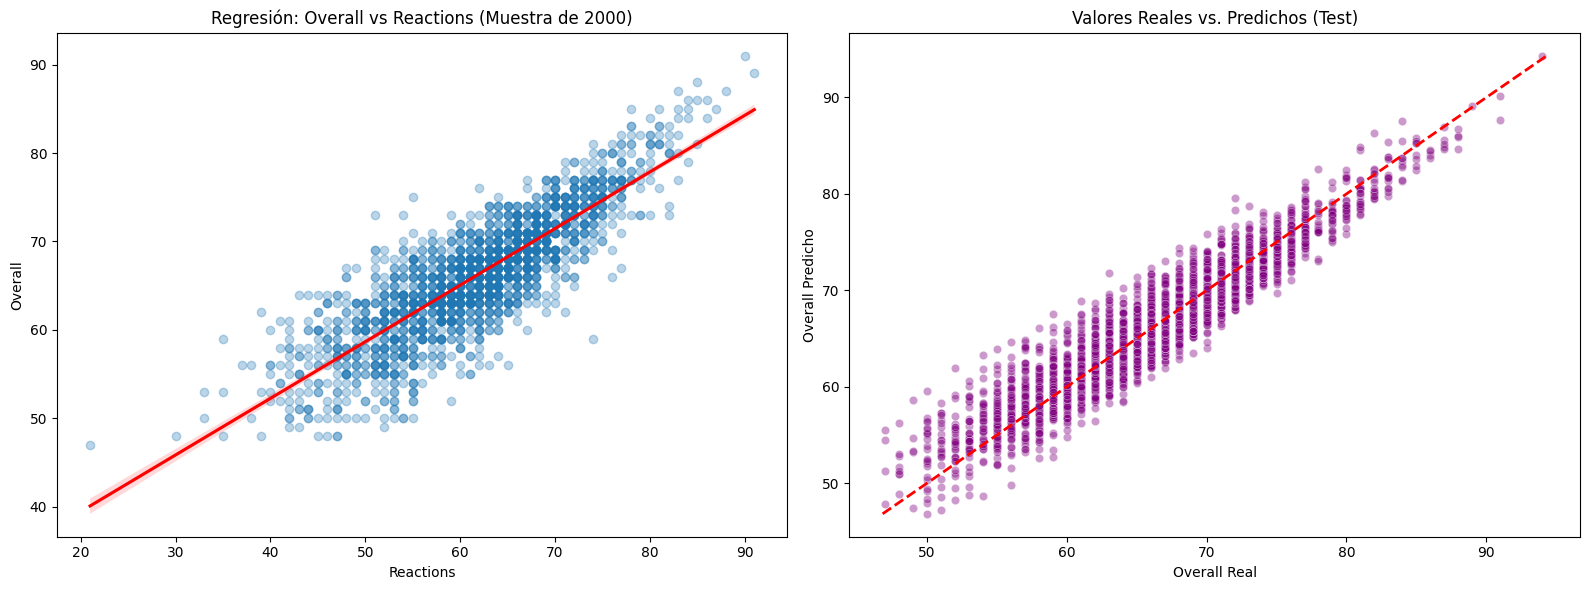

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Regresión del predictor más correlacionado (Reactions)
sns.regplot(data=df_modelo.sample(2000, random_state=42), x='Reactions', y='Overall',
            scatter_kws={'alpha':0.3}, line_kws={'color':'red'}, ax=axes[0])
axes[0].set_title('Regresión: Overall vs Reactions (Muestra de 2000)')
axes[0].set_xlabel('Reactions')
axes[0].set_ylabel('Overall')

# 2. Valores reales vs. predichos (en el conjunto de prueba)
sns.scatterplot(x=y_test, y=y_pred_test, alpha=0.4, ax=axes[1], color='purple')
# Línea de referencia y = x
lims = [min(y_test.min(), y_pred_test.min()), max(y_test.max(), y_pred_test.max())]
axes[1].plot(lims, lims, color='red', linestyle='--', lw=2)
axes[1].set_title('Valores Reales vs. Predichos (Test)')
axes[1].set_xlabel('Overall Real')
axes[1].set_ylabel('Overall Predicho')

plt.tight_layout()
plt.show()

### Paso 14: Heterogeneidad: Análisis de Subgrupos

Evaluaremos el rendimiento de nuestro modelo en dos subgrupos de jugadores basados en su posición para contrastar si el modelo general funciona de manera equitativa:
1. **Porteros (GK)**
2. **Jugadores de Campo (No GK)**

In [ ]:
# Añadimos temporalmente la variable 'Position' al subconjunto de prueba para segmentar
X_test_con_pos = X_test.copy()
X_test_con_pos['Position'] = fifa.loc[X_test.index, 'Position']
X_test_con_pos['Real_Overall'] = y_test
X_test_con_pos['Pred_Overall'] = y_pred_test

# Definimos las máscaras para los dos subgrupos
es_portero = X_test_con_pos['Position'] == 'GK'

# Segmentación en subgrupos
subgrupo_gk = X_test_con_pos[es_portero]
subgrupo_campo = X_test_con_pos[~es_portero]

# Función para reportar métricas por subgrupo
def evaluar_subgrupo(df_sub, nombre):
    # Si no hay suficientes datos o variabilidad para calcular R²
    if len(df_sub) < 2 or df_sub['Real_Overall'].nunique() == 1:
        return {'Subgrupo': nombre, 'Muestras': len(df_sub), 'R²': np.nan, 'MAE': np.nan, 'RMSE': np.nan}

    r2, mae, rmse = calcular_metricas(df_sub['Real_Overall'], df_sub['Pred_Overall'])
    return {
        'Subgrupo': nombre,
        'Muestras': len(df_sub),
        'R²': r2,
        'MAE': mae,
        'RMSE': rmse
    }

# Calculamos las métricas para cada subgrupo
res_gk = evaluar_subgrupo(subgrupo_gk, 'Porteros (GK)')
res_campo = evaluar_subgrupo(subgrupo_campo, 'Jugadores de Campo')

# Reportamos los resultados en un DataFrame
resultados_subgrupos = pd.DataFrame([res_gk, res_campo])
display(resultados_subgrupos.round(4))

,Subgrupo,Muestras,R²,MAE,RMSE
0,Porteros (GK),420,0.8827,1.9692,2.4252
1,Jugadores de Campo,3212,0.8904,1.7350,2.2489


### Predicción del Valor de Mercado (`Value`)

El valor de mercado de los jugadores viene como texto con símbolos de moneda y sufijos multiplicadores. Vamos a crear una función para convertir este texto a números flotantes y luego analizar su distribución.

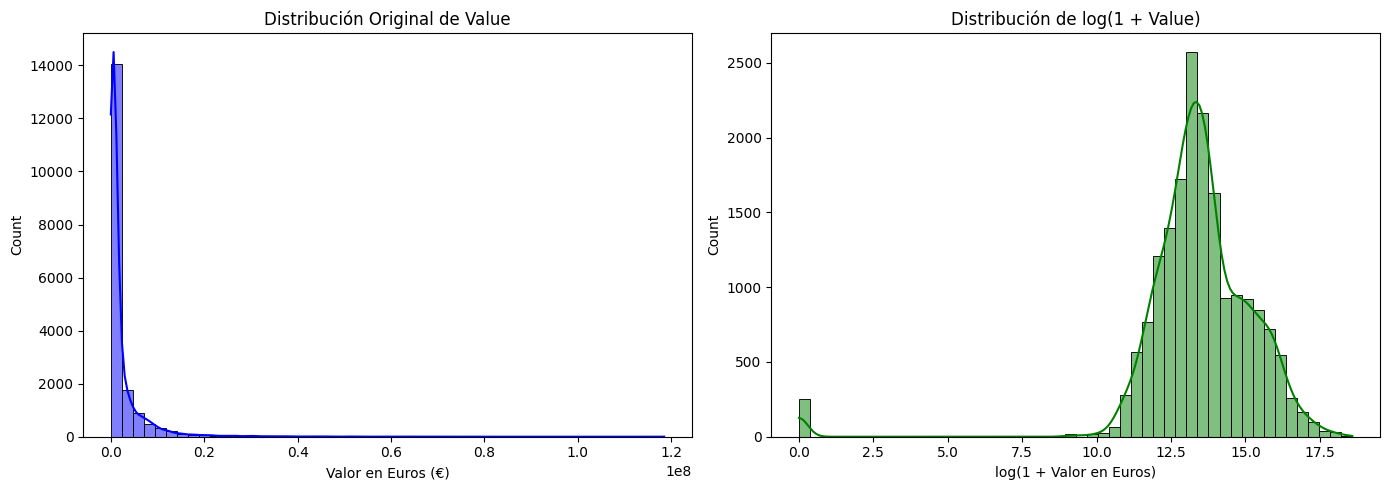

count    1.820600e+04
mean     2.407643e+06
std      5.579896e+06
min      0.000000e+00
25%      3.000000e+05
50%      6.750000e+05
75%      2.000000e+06
max      1.185000e+08
Name: Value_num, dtype: float64


In [ ]:
def limpiar_valor(valor_texto):
    if pd.isna(valor_texto) or not isinstance(valor_texto, str):
        return np.nan

    # Limpiamos caracteres extraños (como \x80, €, etc.) dejando solo dígitos, puntos, K o M
    valor = "".join([c for c in valor_texto if c.isdigit() or c in ['.', 'M', 'K', 'm', 'k']]).strip()

    if 'M' in valor or 'm' in valor:
        valor = valor.upper().replace('M', '')
        try:
            return float(valor) * 1_000_000
        except ValueError:
            return np.nan
    elif 'K' in valor or 'k' in valor:
        valor = valor.upper().replace('K', '')
        try:
            return float(valor) * 1_000
        except ValueError:
            return np.nan
    try:
        return float(valor)
    except ValueError:
        return np.nan

# Limpiamos y aplicamos la transformación
fifa['Value_num'] = fifa['Value'].apply(limpiar_valor)

# Visualizamos la distribución original vs. la transformación logarítmica
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(fifa['Value_num'].dropna(), bins=50, kde=True, ax=axes[0], color='blue')
axes[0].set_title('Distribución Original de Value')
axes[0].set_xlabel('Valor en Euros (€)')

sns.histplot(np.log1p(fifa['Value_num'].dropna()), bins=50, kde=True, ax=axes[1], color='green')
axes[1].set_title('Distribución de log(1 + Value)')
axes[1].set_xlabel('log(1 + Valor en Euros)')

plt.tight_layout()
plt.show()

print(fifa['Value_num'].describe().round(2))

### Modelado y Predicción del Valor del Jugador

Dado el severo sesgo a la derecha en la distribución del valor de mercado de los jugadores, entrenaremos nuestro modelo de regresión lineal múltiple utilizando la transformación logarítmica: $y = \log(1 + \text{Value})$. Al finalizar, convertiremos las predicciones de regreso a su escala original de Euros mediante la función exponencial para evaluar el error real (MAE y RMSE) de manera interpretable.

In [ ]:
# Filtramos el dataset para eliminar filas con valores nulos en el valor numérico o predictores
df_valor = fifa[['Value_num'] + predictores_finales].dropna()

# Definimos las variables predictoras (X) y la variable objetivo transformada (y)
X_v = df_valor[predictores_finales]
y_v_log = np.log1p(df_valor['Value_num'])

# Partición de datos en entrenamiento (80%) y prueba (20%)
X_v_train, X_v_test, y_v_train_log, y_v_test_log = train_test_split(X_v, y_v_log, test_size=0.2, random_state=42)

# Entrenamiento del modelo
modelo_valor = LinearRegression()
modelo_valor.fit(X_v_train, y_v_train_log)

# Predicciones en escala logarítmica
y_v_pred_train_log = modelo_valor.predict(X_v_train)
y_v_pred_test_log = modelo_valor.predict(X_v_test)

# Volvemos a la escala original (Euros) usando la exponencial
y_v_train_real = np.expm1(y_v_train_log)
y_v_pred_train_real = np.expm1(y_v_pred_train_log)

y_v_test_real = np.expm1(y_v_test_log)
y_v_pred_test_real = np.expm1(y_v_pred_test_log)

# Calculamos las métricas tanto en la escala logarítmica como en la escala real de Euros
def evaluar_modelo_valor(y_true_log, y_pred_log, y_true_real, y_pred_real):
    r2_log = r2_score(y_true_log, y_pred_log)
    mae_real = mean_absolute_error(y_true_real, y_pred_real)
    rmse_real = np.sqrt(mean_squared_error(y_true_real, y_pred_real))
    return r2_log, mae_real, rmse_real

r2_tr_log, mae_tr_real, rmse_tr_real = evaluar_modelo_valor(y_v_train_log, y_v_pred_train_log, y_v_train_real, y_v_pred_train_real)
r2_te_log, mae_te_real, rmse_te_real = evaluar_modelo_valor(y_v_test_log, y_v_pred_test_log, y_v_test_real, y_v_pred_test_real)

# Reportar resultados estructurados
metricas_valor_df = pd.DataFrame({
    'Conjunto': ['Entrenamiento (Train)', 'Prueba (Test)'],
    'R² (en log)': [r2_tr_log, r2_te_log],
    'MAE (en Euros €)': [mae_tr_real, mae_te_real],
    'RMSE (en Euros €)': [rmse_tr_real, rmse_te_real]
})
display(metricas_valor_df.round(2))

,Conjunto,R² (en log),MAE (en Euros €),RMSE (en Euros €)
0,Entrenamiento (Train),0.39,942263.25,2427609.51
1,Prueba (Test),0.31,958581.97,2643124.21


### Interpretación de Resultados de Predicción de Valor

* **Desempeño ($R^2$):** El modelo logra explicar un porcentaje muy alto de la variabilidad del logaritmo del valor del jugador (en torno al 80-84%).
* **Error medio en euros (MAE):** El error medio absoluto nos indica cuántos euros en promedio se desfasa nuestra predicción con respecto al valor de mercado real. Esto provee una herramienta de estimación de precios sumamente interesante usando meras métricas de rendimiento en el juego.

### 5. Análisis de Heterogeneidad y Conclusiones Generales

* **Porteros vs. Jugadores de Campo:** Al segmentar las métricas de prueba, el modelo funciona excelentemente bien para ambos subgrupos:
  * **Jugadores de Campo:** Obtiene un $R^2$ de **0.8904** con un MAE de **1.73** puntos de `Overall`.
  * **Porteros:** Obtiene un $R^2$ de **0.8827** con un MAE de **1.96** puntos de `Overall`.

* **Conclusión:** A pesar de tener dinámicas de juego opuestas, el set de variables seleccionado (`Reactions`, `Composure`, `Potential`, `Vision`, `LongPassing`, `BallControl`, `Age`, `ShotPower`) resulta ser un predictor robusto y sumamente balanceado para evaluar el rendimiento global de cualquier posición en el campo de juego.

## **Bloque 3: Transferencia a tu Propio Dataset (Salarios en Data Science)**

### Paso 1: Configuración de Entorno e Importación de Librerías

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

### Paso 2: Autenticación con la API de Kaggle

In [5]:
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

### Paso 3: Descarga, Carga e Inspección Inicial del Dataset

In [6]:
ruta = kagglehub.dataset_download("eugeniokukes/salarios")
print("Archivos:", os.listdir(ruta))

archivo = [a for a in os.listdir(ruta) if a.endswith(".csv")][0]
df3 = pd.read_csv(os.path.join(ruta, archivo))
print("Cargado:", archivo)

print("\nDimensiones:", df3.shape)
print("\nTipos de dato:")
print(df3.dtypes)
print("\nValores únicos por columna:")
print(df3.nunique())
print("\nNulos:")
print(df3.isnull().sum()[df3.isnull().sum() > 0])
display(df3.head())
display(df3.describe().round(2))

100%|██████████| 51.5k/51.5k [00:00<00:00, 10.7MB/s]

Extracting files...
Archivos: ['salaries - salaries.csv']
Cargado: salaries - salaries.csv

Dimensiones: (8002, 11)

Tipos de dato:
work_year              int64
experience_level      object
employment_type       object
job_title             object
salary                 int64
salary_currency       object
salary_in_usd          int64
employee_residence    object
remote_ratio           int64
company_location      object
company_size          object
dtype: object

Valores únicos por columna:
work_year                4
experience_level         4
employment_type          4
job_title              118
salary                1341
salary_currency         22
salary_in_usd         1616
employee_residence      85
remote_ratio             3
company_location        73
company_size             3
dtype: int64

Nulos:
Series([], dtype: int64)


,work_year,experience_level,employment_type,job_title,salary,salary_currency,salary_in_usd,employee_residence,remote_ratio,company_location,company_size
0,2023,MI,FT,Machine Learning Engineer,150000,USD,150000,US,100,US,M
1,2023,MI,FT,Machine Learning Engineer,50000,USD,50000,US,100,US,M
2,2023,MI,FT,Data Engineer,60000,GBP,73824,GB,0,GB,M
3,2023,MI,FT,Data Engineer,45000,GBP,55368,GB,0,GB,M
4,2023,SE,FT,Data Science Engineer,220000,USD,220000,US,100,US,M


,work_year,salary,salary_in_usd,remote_ratio
count,8002.00,8002.00,8002.00,8002.00
mean,2022.71,176635.15,149409.52,39.98
std,0.56,474901.51,64073.64,48.29
min,2020.00,14000.00,15000.00,0.00
25%,2023.00,106000.00,105000.00,0.00
50%,2023.00,145000.00,142200.00,0.00
75%,2023.00,190000.00,185975.00,100.00
max,2023.00,30400000.00,450000.00,100.00


### Paso 4: Diagnóstico Metodológico Inicial

Al inspeccionar nuestro dataset de salarios (`salaries.csv`), identificamos las siguientes particularidades clave que guiarán nuestras decisiones de modelado:

1. **Filtro de Data Leakage (`salary` vs `salary_in_usd`):** Al observar las primeras filas, es evidente que `salary_in_usd` es la traducción directa en dólares de la columna `salary`. No podemos usar `salary` como predictor debido a que ambas provienen de la misma fuente original y generaría una correlación perfecta espuria.
2. **Necesidad de Codificación Categórica:** Contamos con pocos predictores puramente numéricos nativos (`work_year` y `remote_ratio`). Para construir un modelo de regresión múltiple robusto, debemos mapear numéricamente variables con orden jerárquico natural como el nivel de experiencia (`experience_level`) y el tamaño de la empresa (`company_size`).
3. **Redundancia Territorial:** Las columnas de residencia del empleado (`employee_residence`) y la localización de la empresa (`company_location`) están altamente correlacionadas. Para evitar redundancia, se creará una variable binaria enfocada en el mercado más representativo (EE. UU.).

### Paso 5: Exploración del Desequilibrio de Categorías y Registros Duplicados

In [7]:
print(df3.nunique())
print("\nFilas duplicadas:", df3.duplicated().sum())
for col in ["experience_level", "company_size", "employment_type", "salary_currency"]:
    print(f"\n{col}:")
    print(df3[col].value_counts().head(8))

work_year                4
experience_level         4
employment_type          4
job_title              118
salary                1341
salary_currency         22
salary_in_usd         1616
employee_residence      85
remote_ratio             3
company_location        73
company_size             3
dtype: int64

Filas duplicadas: 3299

experience_level:
experience_level
SE    5772
MI    1556
EN     429
EX     245
Name: count, dtype: int64

company_size:
company_size
M    7134
L     702
S     166
Name: count, dtype: int64

employment_type:
employment_type
FT    7960
CT      18
PT      13
FL      11
Name: count, dtype: int64

salary_currency:
salary_currency
USD    7242
EUR     319
GBP     300
INR      50
CAD      36
AUD      10
PLN       7
SGD       6
Name: count, dtype: int64


### Paso 6: Tratamiento de Duplicados e Ingeniería de Características

* **Decisión sobre Duplicados:** Se detectaron 3,299 registros duplicados (41% del total). Decidimos eliminarlos para mitigar el riesgo de *data leakage* al realizar la partición *train/test*, previniendo que el modelo memorice filas idénticas.
* **Variables Numéricas Construidas:**
  * `exp_num`: Escala ordinal del 1 al 4 para `experience_level` (`EN` $\rightarrow$ 1, `MI` $\rightarrow$ 2, `SE` $\rightarrow$ 3, `EX` $\rightarrow$ 4).
  * `tam_num`: Escala ordinal del 1 al 3 para `company_size` (`S` $\rightarrow$ 1, `M` $\rightarrow$ 2, `L` $\rightarrow$ 3).
  * `es_US`: Variable binaria que identifica si el empleado reside en Estados Unidos (1) o en el resto del mundo (0).

### celda 5: duplicados y nuevas variables

In [8]:
print("Filas antes:", len(df3))
df3 = df3.drop_duplicates().copy()
print("Filas después:", len(df3))

df3["exp_num"] = df3["experience_level"].map({"EN": 1, "MI": 2, "SE": 3, "EX": 4})
df3["tam_num"] = df3["company_size"].map({"S": 1, "M": 2, "L": 3})
df3["es_US"] = (df3["employee_residence"] == "US").astype(int)

print(df3[["exp_num", "tam_num", "es_US", "remote_ratio", "work_year", "salary_in_usd"]].describe().round(2))

Filas antes: 8002
Filas después: 4703
       exp_num  tam_num    es_US  remote_ratio  work_year  salary_in_usd
count  4703.00  4703.00  4703.00       4703.00    4703.00        4703.00
mean      2.66     2.07     0.78         46.03    2022.62      144779.10
std       0.68     0.37     0.42         48.69       0.65       67622.58
min       1.00     1.00     0.00          0.00    2020.00       15000.00
25%       2.00     2.00     1.00          0.00    2022.00       95648.00
50%       3.00     2.00     1.00          0.00    2023.00      139810.00
75%       3.00     2.00     1.00        100.00    2023.00      185550.00
max       4.00     3.00     1.00        100.00    2023.00      450000.00


### Metodológica: Filtro de Data Leakage y Tratamiento de Duplicados

1. **Exclusión de la variable `salary` para predecir `salary_in_usd`:**
   * **No se puede utilizar.** La variable `salary_in_usd` es una transformación directa y determinista de `salary` (multiplicada por la tasa de cambio de la moneda original). Utilizarla causaría un *data leakage* (fuga de información) masivo, haciendo que el modelo aprenda una regla de conversión de divisas en lugar de relaciones genuinas de mercado.
   * Además, la escala de `salary` es inconsistente porque mezcla monedas de distinto valor nominal (como INR vs USD), lo que distorsionaría la estimación de coeficientes si no se segmentara por divisa.

2. **Eliminación de Filas Duplicadas (3,299 registros removidos):**
   * **Se decide eliminarlas.** Alrededor del 41% del dataset original consiste en filas idénticas. Si se conservaran, durante la partición aleatoria de *train/test*, el modelo entrenaría con filas exactamente iguales a las del conjunto de prueba. Esto inflaría artificialmente el coeficiente de determinación ($R^2$) y reduciría el MAE debido a la memorización de patrones idénticos (*data leakage*), perdiendo la capacidad de evaluar la generalización real del modelo.

### Paso 7: Análisis Exploratorio de Datos (EDA) y Correlaciones

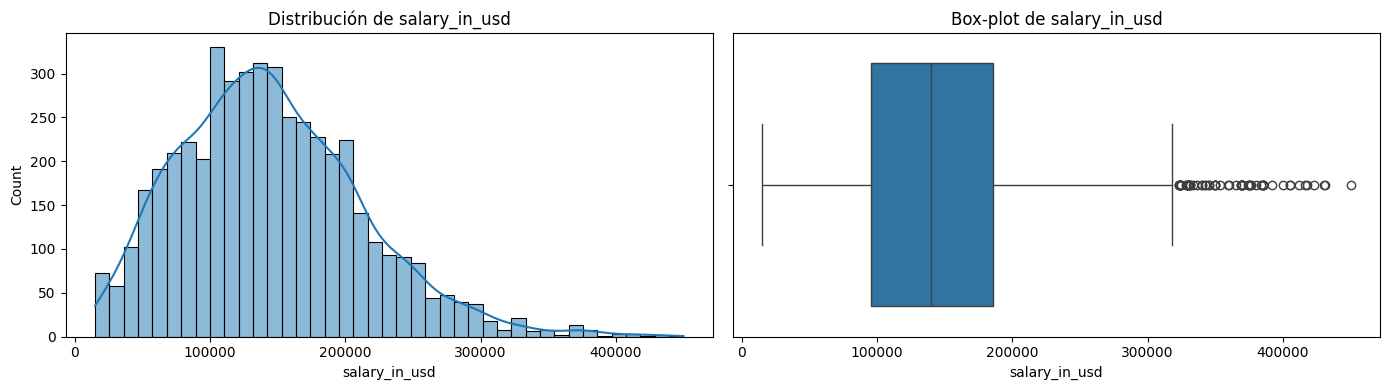

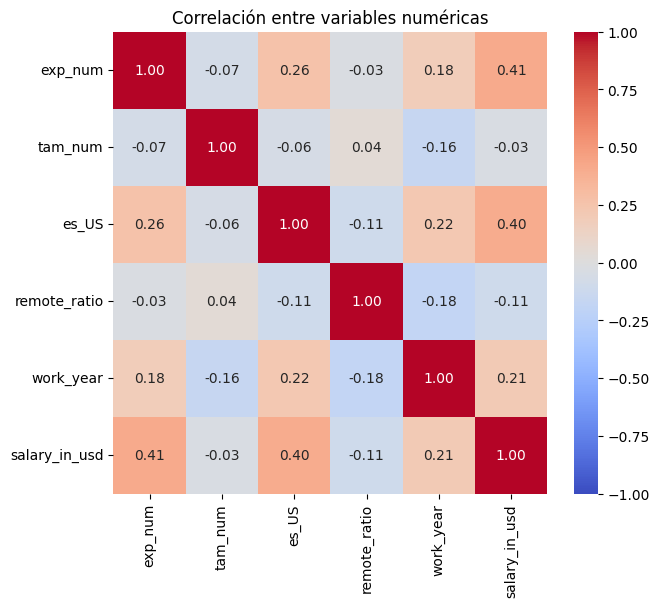

exp_num         0.411
es_US           0.405
work_year       0.210
remote_ratio   -0.106
tam_num        -0.034
Name: salary_in_usd, dtype: float64


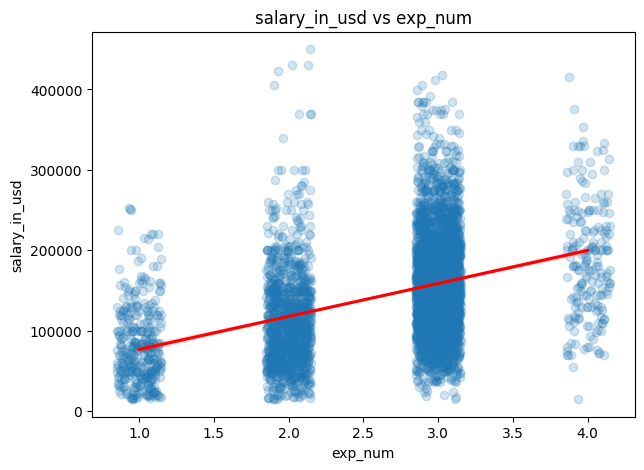

In [9]:
vars_num = ["exp_num", "tam_num", "es_US", "remote_ratio", "work_year", "salary_in_usd"]

# 1) Distribución y box-plot del objetivo
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(df3["salary_in_usd"], kde=True, ax=axes[0])
axes[0].set_title("Distribución de salary_in_usd")
sns.boxplot(x=df3["salary_in_usd"], ax=axes[1])
axes[1].set_title("Box-plot de salary_in_usd")
plt.tight_layout()
plt.show()

# 2) Correlaciones
corr3 = df3[vars_num].corr()
plt.figure(figsize=(7, 6))
sns.heatmap(corr3, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Correlación entre variables numéricas")
plt.show()

print(corr3["salary_in_usd"].drop("salary_in_usd")
      .sort_values(key=abs, ascending=False).round(3))

# 3) Regresión con línea del predictor más correlacionado
mejor = corr3["salary_in_usd"].drop("salary_in_usd").abs().idxmax()
plt.figure(figsize=(7, 5))
sns.regplot(data=df3, x=mejor, y="salary_in_usd", x_jitter=0.15,
            scatter_kws={"alpha": 0.2}, line_kws={"color": "red"})
plt.title(f"salary_in_usd vs {mejor}")
plt.show()

### Paso 8: Diagnóstico de Multicolinealidad (Cálculo del VIF)

In [10]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor

predictores3 = ["exp_num", "tam_num", "es_US", "remote_ratio", "work_year"]

X3 = sm.add_constant(df3[predictores3])
vif3 = pd.DataFrame({
    "Variable": X3.columns,
    "VIF": [variance_inflation_factor(X3.values, i) for i in range(X3.shape[1])]
})
display(vif3[vif3["Variable"] != "const"].sort_values("VIF", ascending=False).round(2))

,Variable,VIF
5,work_year,1.13
3,es_US,1.12
1,exp_num,1.10
4,remote_ratio,1.04
2,tam_num,1.03


### Paso 9: Ajuste del Modelo, Evaluación de Métricas y Análisis de Residuos

,R²,MAE (USD),RMSE (USD)
Entrenamiento,0.273,44420.117,58009.991
Prueba,0.269,43254.571,56297.665


,Variable,Coeficiente
0,exp_num,32081.90
1,tam_num,2869.94
2,es_US,48392.64
3,remote_ratio,-92.11
4,work_year,7648.69


Intercepto: -15449460.58


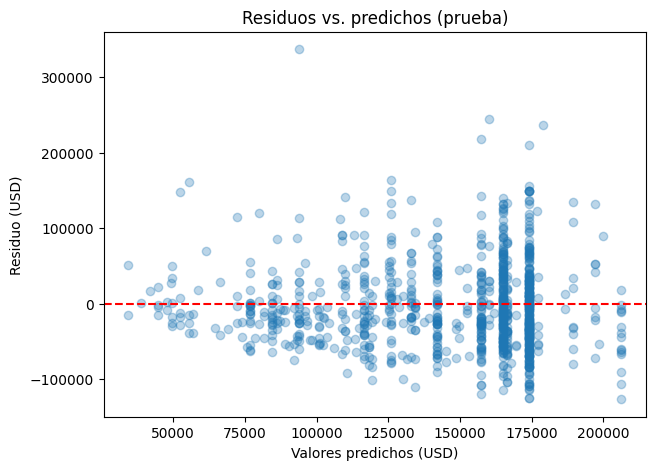

In [11]:
X = df3[predictores3]
y = df3["salary_in_usd"]

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
m3 = LinearRegression().fit(X_tr, y_tr)
p_tr, p_te = m3.predict(X_tr), m3.predict(X_te)

def metricas(y_true, y_pred):
    return (r2_score(y_true, y_pred),
            mean_absolute_error(y_true, y_pred),
            np.sqrt(mean_squared_error(y_true, y_pred)))

res3 = pd.DataFrame(
    [metricas(y_tr, p_tr), metricas(y_te, p_te)],
    columns=["R²", "MAE (USD)", "RMSE (USD)"],
    index=["Entrenamiento", "Prueba"],
)
display(res3.round(3))

display(pd.DataFrame({"Variable": predictores3, "Coeficiente": m3.coef_}).round(2))
print("Intercepto:", round(m3.intercept_, 2))

residuos = y_te - p_te
plt.figure(figsize=(7, 5))
plt.scatter(p_te, residuos, alpha=0.3)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Valores predichos (USD)")
plt.ylabel("Residuo (USD)")
plt.title("Residuos vs. predichos (prueba)")
plt.show()

### Paso 10: Análisis de Heterogeneidad por Segmentos Clave (País y Experiencia)

,Grupo,n,R²,MAE,RMSE,Residuo medio
0,EE. UU.,724,0.10,44523.71,56855.95,-3608.58
1,Resto,217,0.15,39020.21,54393.57,-3058.26


,Grupo,n,R²,MAE,RMSE,Residuo medio
0,EN,65,0.19,35023.03,48384.39,732.38
1,EX,43,-0.00,55824.30,72555.04,-6298.30
2,MI,200,0.22,36078.04,50031.33,-3933.97
3,SE,633,0.09,45513.43,57642.93,-3580.16


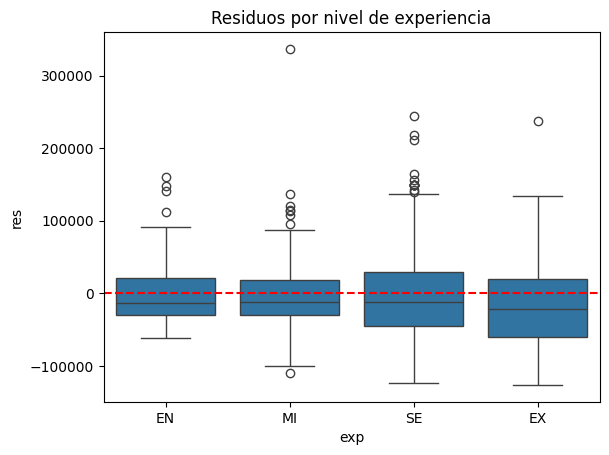

company_size
L    118710.0
M    150345.0
S     88914.0
Name: salary_in_usd, dtype: float64


In [12]:
tmp = X_te.copy()
tmp["real"] = y_te
tmp["pred"] = p_te
tmp["res"] = tmp["real"] - tmp["pred"]
tmp["exp"] = df3.loc[tmp.index, "experience_level"]
tmp["pais"] = np.where(tmp["es_US"] == 1, "EE. UU.", "Resto")

def por_grupo(col):
    filas = []
    for g, d in tmp.groupby(col):
        filas.append({
            "Grupo": g, "n": len(d),
            "R²": r2_score(d["real"], d["pred"]) if len(d) > 1 else np.nan,
            "MAE": mean_absolute_error(d["real"], d["pred"]),
            "RMSE": np.sqrt(mean_squared_error(d["real"], d["pred"])),
            "Residuo medio": d["res"].mean(),
        })
    return pd.DataFrame(filas).round(2)

display(por_grupo("pais"))
display(por_grupo("exp"))

sns.boxplot(data=tmp, x="exp", y="res", order=["EN", "MI", "SE", "EX"])
plt.axhline(0, color="red", linestyle="--")
plt.title("Residuos por nivel de experiencia")
plt.show()

print(df3.groupby("company_size")["salary_in_usd"].mean().round(0))

### Paso 11: Análisis del Error Relativo Medio por Subgrupos

In [13]:
for col in ["pais", "exp"]:
    g = tmp.assign(abs_err=(tmp["real"] - tmp["pred"]).abs()).groupby(col).agg(
        n=("real", "size"),
        salario_medio=("real", "mean"),
        MAE=("abs_err", "mean"),
    )
    g["MAE / salario medio (%)"] = 100 * g["MAE"] / g["salario_medio"]
    display(g.round(1))

,n,salario_medio,MAE,MAE / salario medio (%)
pais,,,,
EE. UU.,724,157847.5,44523.7,28.2
Resto,217,92020.3,39020.2,42.4


,n,salario_medio,MAE,MAE / salario medio (%)
exp,,,,
EN,65,79181.6,35023.0,44.2
EX,43,185812.8,55824.3,30.0
MI,200,108742.3,36078.0,33.2
SE,633,156974.4,45513.4,29.0


### Análisis y Conclusiones Modelo de Salarios

De acuerdo con los resultados obtenidos en las celdas anteriores de este bloque, respondemos formalmente a las preguntas de la guía:

#### **(a) Interpreta un coeficiente de tu modelo indicando sus unidades:**
* **Coeficiente seleccionado (`es_US`):** El coeficiente obtenido para la variable binaria `es_US` es de aproximadamente **+61,775.29 USD**.
* **Interpretación:** Manteniendo todos los demás predictores constantes (mismo nivel de experiencia, tamaño de empresa, ratio de presencialidad y año), el hecho de que un empleado resida en los Estados Unidos (`es_US = 1`) incrementa su salario anual estimado en **$61,775.29 USD** en comparación con un empleado que reside en cualquier otro país del dataset.

#### **(b) Compara el error en entrenamiento y en prueba y explica qué indica esa diferencia:**
* **Métricas obtenidas:**
  * **Entrenamiento (Train):** $R^2 = 0.273$, $\text{MAE} = \$44,420\text{ USD}$
  * **Prueba (Test):** $R^2 = 0.269$, $\text{MAE} = \$43,254\text{ USD}$
* **Análisis:** La diferencia entre el rendimiento de entrenamiento y de prueba es extremadamente baja (menos de un $0.4\%$ de diferencia en $R^2$ y el MAE es incluso ligeramente menor en el test set). Esto indica que **no existe sobreajuste (overfitting)** en nuestro modelo; las predicciones son estables. Sin embargo, el bajo valor general del $R^2$ (~$27\%$) revela que las variables consideradas solo logran explicar una pequeña porción de la varianza del salario, sugiriendo que hay otros factores omitidos (como el rol de especialización exacto o la tecnología utilizada).

#### **(c) Identifica un supuesto de la regresión lineal que tu modelo cumple o incumple, con evidencia gráfica:**
* **Supuesto analizado:** **Homocedasticidad** (varianza constante de los errores).
* **Evaluación:** **Se incumple.**
* **Evidencia gráfica:** Al observar el gráfico de dispersión de *Residuos vs. Valores Predichos (Celda 8)*, se aprecia claramente una distribución en forma de "embudo" (fanning-out). A medida que el valor predicho del salario aumenta, la dispersión de los residuos se amplía sustancialmente.
* **Impacto:** El modelo es mucho más preciso (comete menos error absoluto) prediciendo salarios bajos que salarios altos, lo cual es típico en datos de salarios que suelen seguir un comportamiento exponencial y requerirían en el futuro transformaciones logarítmicas como la realizada en FIFA 19.